# MLP from Scratch — Classificação das três classes da Iris

**Trabalho 5 — Visão Computacional / Aprendizado de Máquina**

Gustavo Gabriel Ripka — GRR20203935
Arthur Barreto Godoi — GRR20224377

Este notebook estuda a implementação de **MLP (Multi-Layer Perceptron) from scratch**
apresentada em aula (adaptada do notebook de Vítor Gama Lemos). O objetivo é:

1. **Estudar e depurar** a implementação (vários bugs foram encontrados e corrigidos);
2. Descobrir **como classificar bem as três classes** de flores Iris;
3. Analisar **convergência, erros e overfitting**.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn
from sklearn.datasets import load_iris

seaborn.set(style='whitegrid'); seaborn.set_context('talk')
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

np.random.seed(0)
random.seed(123)

iris_data = load_iris()
print('Amostras:', iris_data.data.shape[0], '| Atributos:', iris_data.data.shape[1])
print('Classes:', list(iris_data.target_names))

Amostras: 150 | Atributos: 4
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


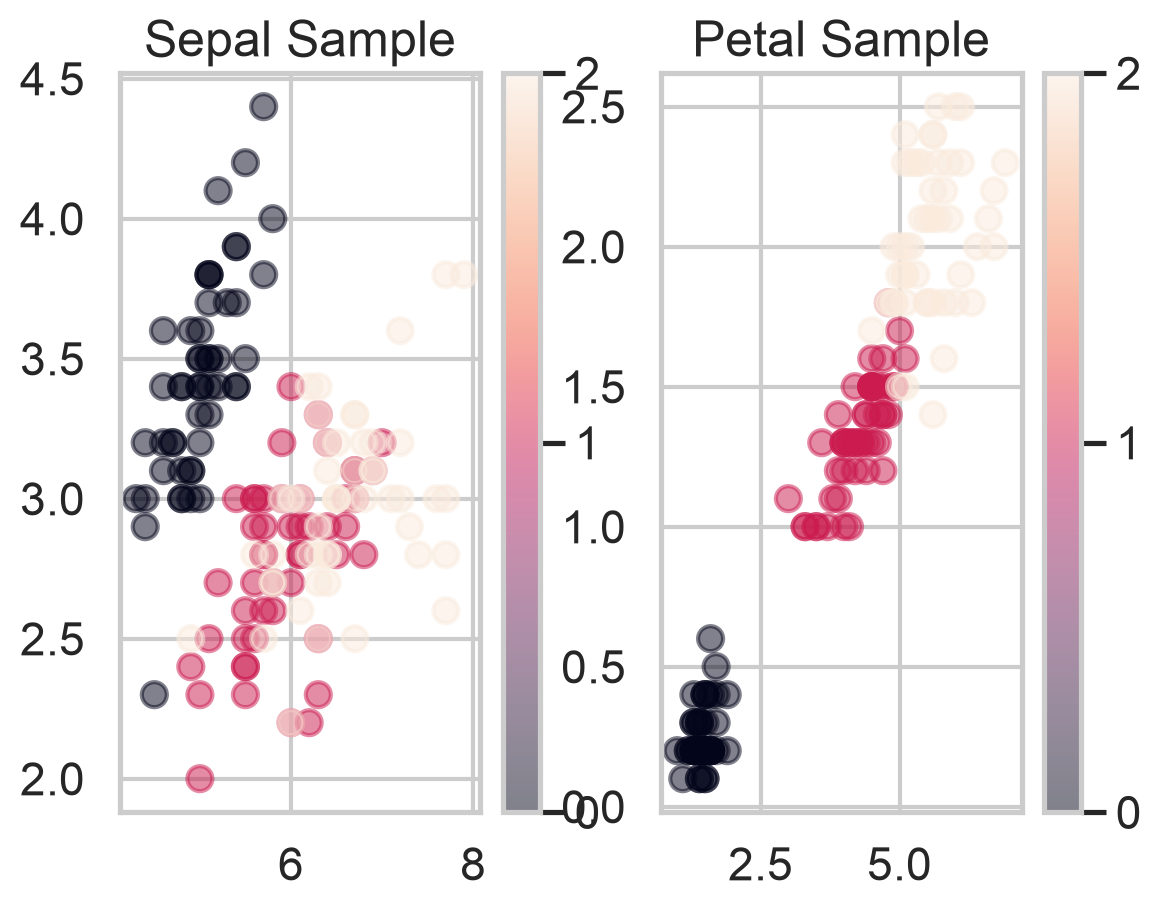

In [2]:
# Visualização das amostras por par de atributos (sépala e pétala)
plt.subplot(1, 2, 1)
plt.scatter(iris_data.data[:,0], iris_data.data[:,1], alpha=0.5, c=iris_data.target)
plt.colorbar(ticks=([0, 1, 2]))
plt.title('Sepal Sample');

plt.subplot(1, 2, 2)
plt.scatter(iris_data.data[:,2], iris_data.data[:,3], alpha=0.5, c=iris_data.target)
plt.colorbar(ticks=([0, 1, 2]))
plt.title('Petal Sample');

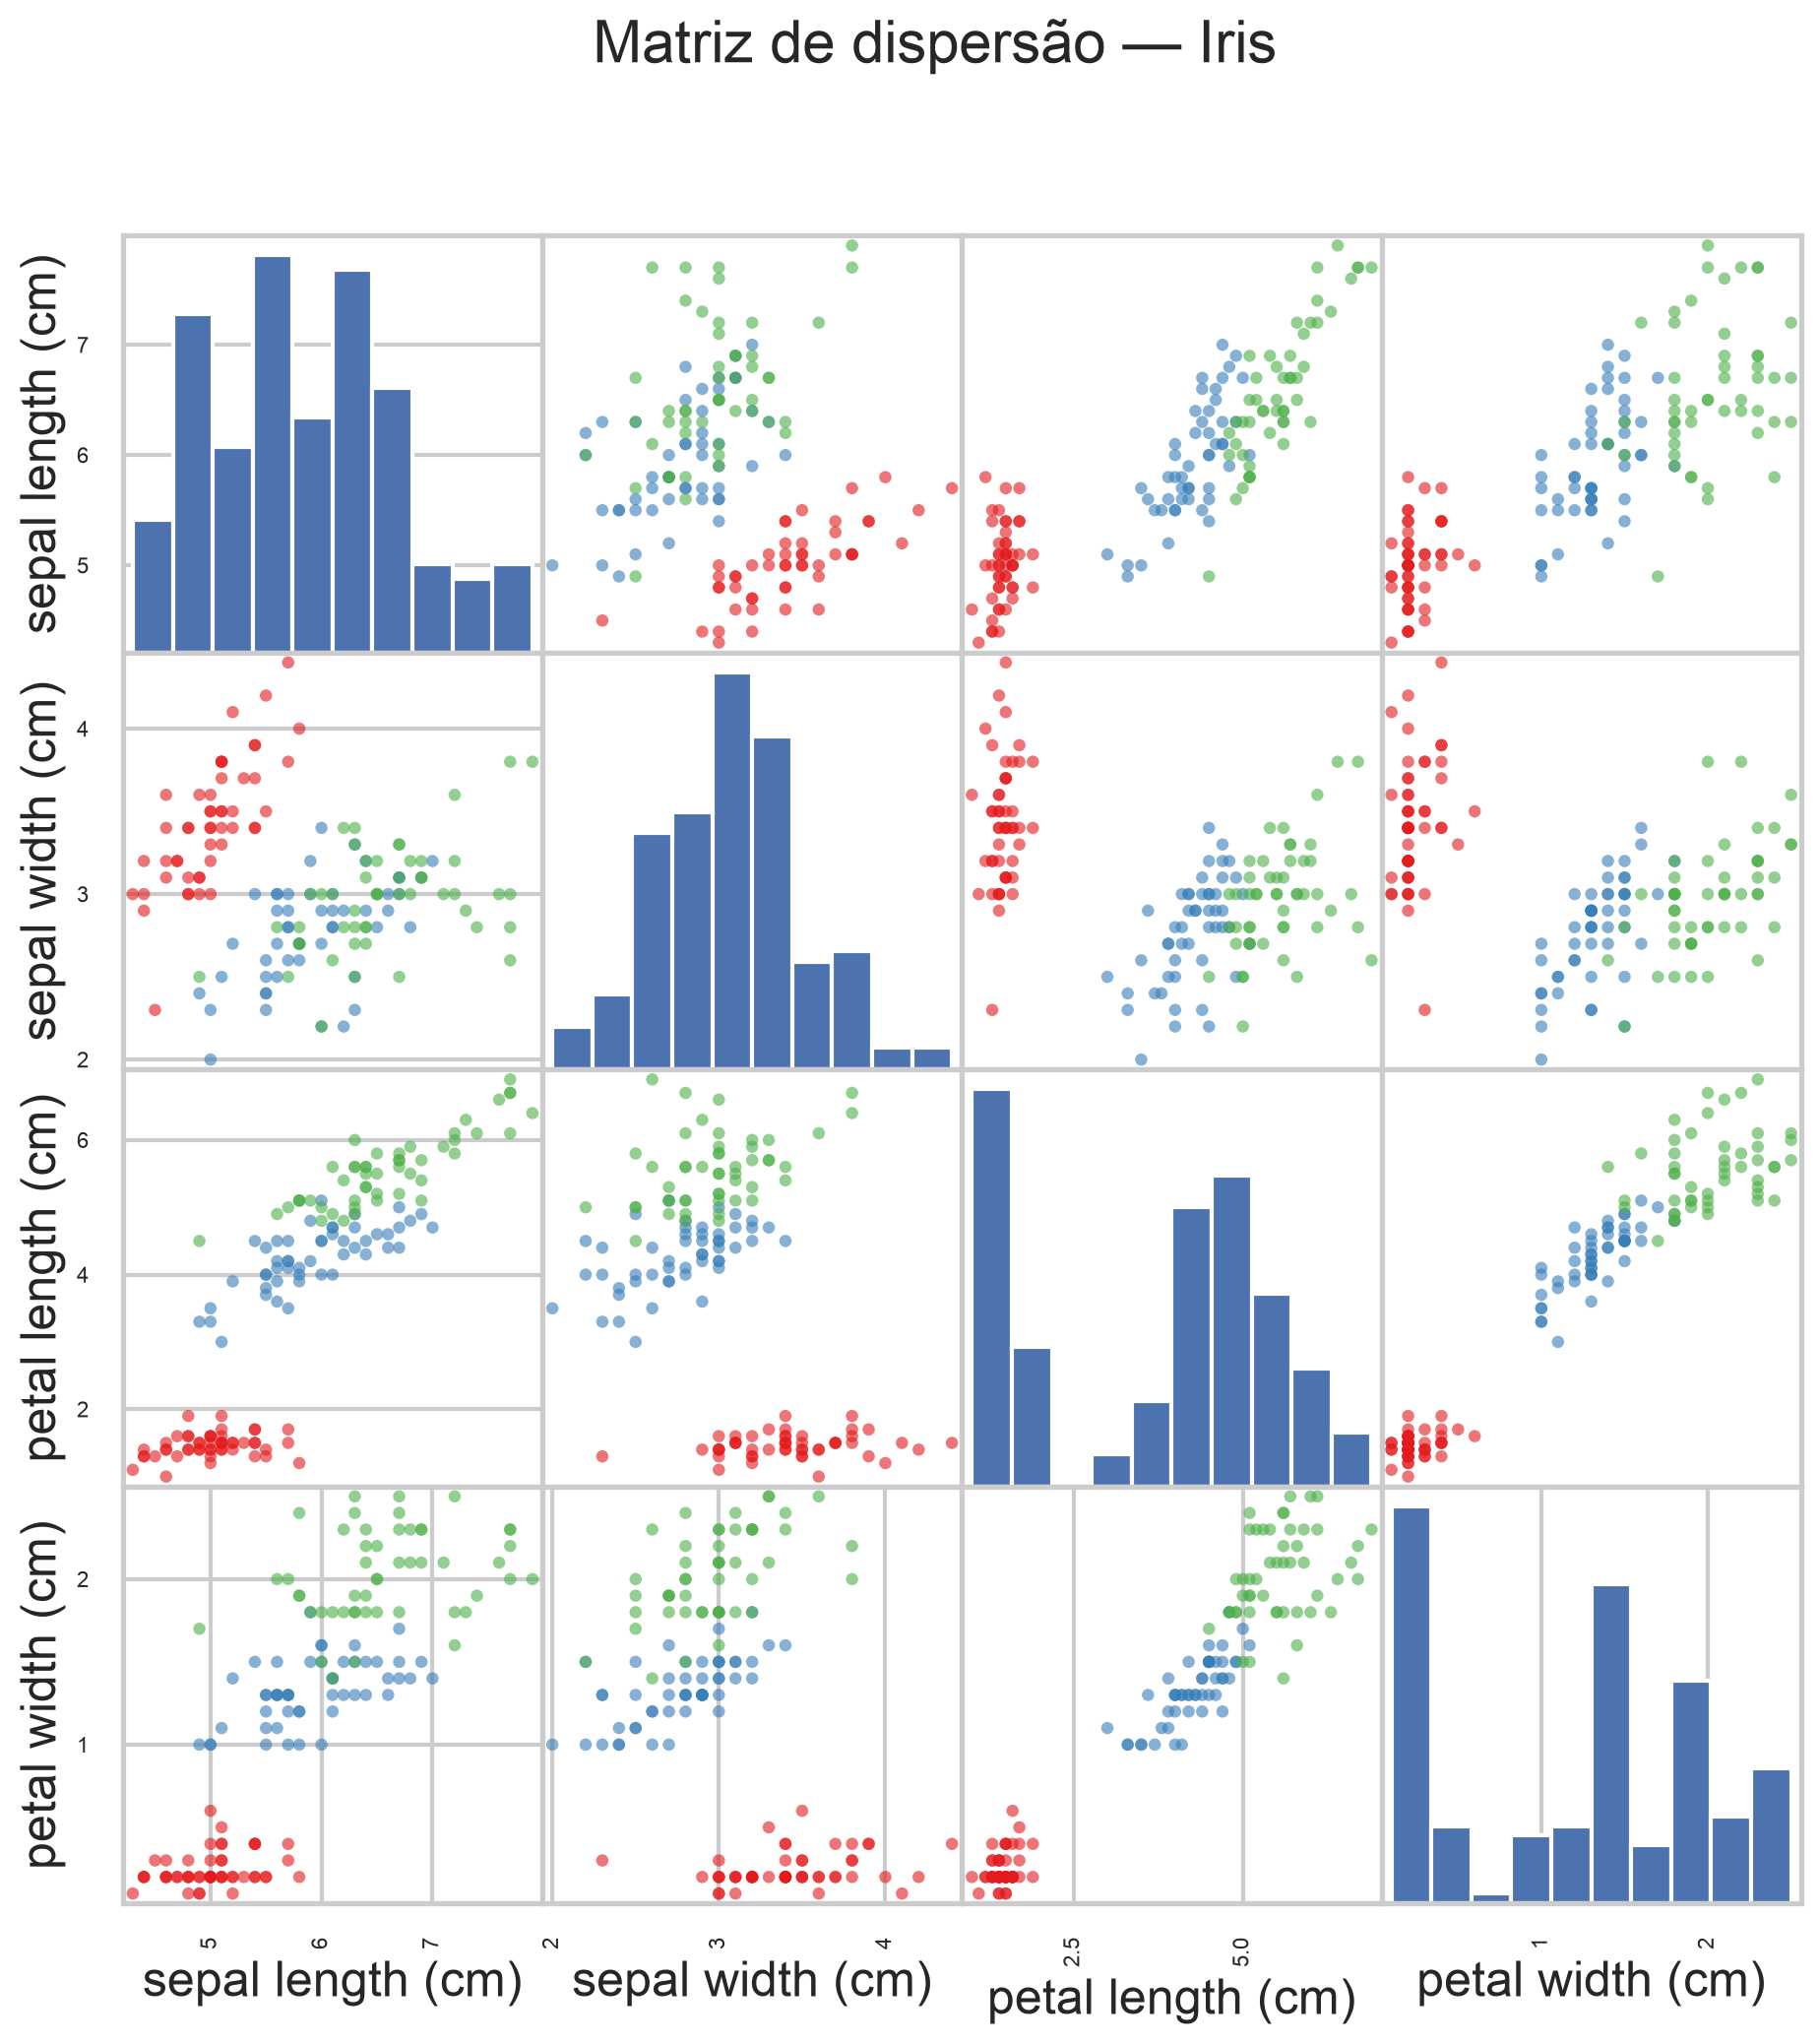

In [3]:
# Matriz de dispersão com as classes coloridas
df = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)
df['target'] = iris_data.target
df['target_name'] = df['target'].apply(lambda i: iris_data.target_names[i])

cores = dict(zip(iris_data.target_names, ['#e41a1c', '#377eb8', '#4daf4a']))
axes = pd.plotting.scatter_matrix(df[iris_data.feature_names], figsize=(11, 11),
                                  c=df['target'].map(
                                      dict(enumerate(iris_data.target_names))).map(cores),
                                  alpha=0.6, diagonal='hist')
plt.suptitle('Matriz de dispersão — Iris');

## Separação treino/teste — e um bug grave de preparação dos dados

O notebook original preparava os dados assim:

```python
random.shuffle(iris_dataset)          # ndarray 150×5
train_X, test_X, train_y, test_y = train_test_split(..., stratify=y)
```

**Bug (6):** `random.shuffle` do módulo `random` **não funciona em arrays 2D do
NumPy**. A troca `x[i], x[j] = x[j], x[i]` cria *views* que se sobrescrevem: a
operação vira `x[i] = x[j]` duas vezes — linhas são **duplicadas** e outras
**perdidas**. A célula abaixo demonstra: após o shuffle "ingênuo", as 150
amostras deixam de ser 50/50/50 e a classe *virginica* quase desaparece — era
isso que impedia classificar bem as três classes.

A correção é embaralhar **índices** (ou deixar o `train_test_split` fazer tudo).
Usamos divisão **estratificada** 80/20 (`random_state=11`).

In [4]:
from sklearn.model_selection import train_test_split

iris_dataset = np.column_stack((iris_data.data, iris_data.target.T))
print('Distribuição original (50/50/50):', np.bincount(iris_data.target))

# --- Demonstração do bug: random.shuffle em ndarray 2D corrompe os dados ---
copia = iris_dataset.copy()
random.seed(123)
random.shuffle(copia)                       # troca vira duplicação (views aliasadas)
print('Após random.shuffle ingênuo:', np.bincount(copia[:, 4].astype(int)),
      ' <- linhas duplicadas/perdidas!')

# --- Correção: embaralhar índices ---
random.seed(123)
ordem = np.array(random.sample(range(len(iris_dataset)), len(iris_dataset)))
iris_dataset = iris_dataset[ordem]
print('Após embaralhar índices:', np.bincount(iris_dataset[:, 4].astype(int)))

X = iris_dataset[:, :4]
y = iris_dataset[:, 4]

train_X, test_X, train_y, test_y = train_test_split(
    X, y, test_size=0.2, random_state=11, stratify=y)

print('Treino:', train_X.shape, '| Teste:', test_X.shape)
print('Distribuição treino:', np.bincount(train_y.astype(int)),
      '| teste:', np.bincount(test_y.astype(int)))

Distribuição original (50/50/50): [50 50 50]
Após random.shuffle ingênuo: [102  42   6]  <- linhas duplicadas/perdidas!
Após embaralhar índices: [50 50 50]
Treino: (120, 4) | Teste: (30, 4)
Distribuição treino: [40 40 40] | teste: [10 10 10]


## Implementação original: bugs encontrados

Estudando o código original, identificamos e corrigimos os seguintes problemas:

| # | Bug | Efeito |
|---|-----|--------|
| 1 | `predict()` **não aplicava a função de ativação** na propagação direta | a rede era avaliada como um modelo **linear** (sem não-linearidade), destruindo a acurácia |
| 2 | `total_error` **nunca era zerado entre épocas** | o erro exibido **crescia monotonicamente** — parecia que a rede nunca convergia, mesmo melhorando |
| 3 | fator arbitrário `0.05` no erro quadrático e registro apenas a cada 50 épocas | curva de erro distorcida e sem resolução para análise de convergência |
| 4 | typo `iasHiddenValue` e ausência de semente própria | branch padrão quebrado; execuções não reprodutíveis |
| 5 | `random.shuffle` do módulo `random` sobre o **ndarray 2D** de dados | trocas viram duplicações (*views* aliasadas): linhas perdidas/duplicadas — a Iris deixava de ser 50/50/50 e a *virginica* quase desaparecia |

A célula a seguir traz a **classe corrigida** (comentários marcam cada correção).
O algoritmo de backpropagation em si estava **correto** e foi preservado. A
ausência de normalização dos atributos **não é um bug** — mas, como veremos nos
experimentos, ela interage fortemente com o learning rate.

In [5]:
# Implementação do Multilayer Perceptron (versão corrigida)
from sklearn.base import BaseEstimator, ClassifierMixin

class MultiLayerPerceptron(BaseEstimator, ClassifierMixin):
    '''MLP com uma camada oculta treinada por backpropagation.

    Correções em relação à implementação original:
      1. predict/forward agora aplicam a função de ativação nas duas camadas;
      2. o erro é calculado POR ÉPOCA (o original acumulava entre épocas);
      3. MSE padrão (sem o fator 0.05), registrado em todas as épocas;
      4. typo 'iasHiddenValue' corrigido e semente própria para os pesos;
      5. histórico de acurácia treino/teste para análise de overfitting.
    '''
    def __init__(self, params=None, seed=None):
        self.params = params

        if params is None:
            self.inputLayer = 4            # camada de entrada
            self.hiddenLayer = 5           # camada oculta
            self.outputLayer = 3           # camada de saída
            self.learningRate = 0.005
            self.max_epochs = 600
            self.BiasHiddenValue = -1      # correção (5): antes 'iasHiddenValue'
            self.BiasOutputValue = -1
            self.activation = self.ativacao['sigmoid']
            self.deriv = self.derivada['sigmoid']
        else:
            self.inputLayer = params['InputLayer']
            self.hiddenLayer = params['HiddenLayer']
            self.outputLayer = params['OutputLayer']
            self.learningRate = params['LearningRate']
            self.max_epochs = params['Epocas']
            self.BiasHiddenValue = params['BiasHiddenValue']
            self.BiasOutputValue = params['BiasOutputValue']
            self.activation = self.ativacao[params['ActivationFunction']]
            self.deriv = self.derivada[params['ActivationFunction']]

        if seed is not None:
            random.seed(seed)              # correção (4): reprodutibilidade

        self.WEIGHT_hidden = self.starting_weights(self.inputLayer, self.hiddenLayer)
        self.WEIGHT_output = self.starting_weights(self.hiddenLayer, self.outputLayer)

        self.BIAS_hidden = np.array([self.BiasHiddenValue for _ in range(self.hiddenLayer)])
        self.BIAS_output = np.array([self.BiasOutputValue for _ in range(self.outputLayer)])
        self.classes_number = self.outputLayer

    # Pesos aleatórios em [-1, +1], como no original (agora como np.array)
    def starting_weights(self, rows, columns):
        return np.array([[2 * random.random() - 1 for _ in range(columns)]
                         for _ in range(rows)])

    ativacao = {
        'sigmoid': (lambda x: 1/(1 + np.exp(-x))),
        'tanh':    (lambda x: np.tanh(x)),
        'Relu':    (lambda x: x * (x > 0)),
    }
    derivada = {
        'sigmoid': (lambda x: x * (1 - x)),
        'tanh':    (lambda x: 1 - x**2),
        'Relu':    (lambda x: 1 * (x > 0)),
    }

    def Backpropagation_Algorithm(self, x):
        # Etapa 1 - Erro na saída (alvo - previsto)
        ERROR_output = self.output - self.OUTPUT_L2
        DELTA_output = (-1) * (ERROR_output) * self.deriv(self.OUTPUT_L2)

        # Etapa 2 - Atualiza pesos oculta->saída (gradiente descendente)
        for i in range(self.hiddenLayer):
            for j in range(self.outputLayer):
                self.WEIGHT_output[i][j] -= (self.learningRate * (DELTA_output[j] * self.OUTPUT_L1[i]))
                self.BIAS_output[j] -= (self.learningRate * DELTA_output[j])

        # Etapa 3 - Erro retropropagado para a camada oculta
        delta_hidden = np.matmul(self.WEIGHT_output, DELTA_output) * self.deriv(self.OUTPUT_L1)

        # Etapa 4 - Atualiza pesos entrada->oculta
        for i in range(self.inputLayer):
            for j in range(self.hiddenLayer):
                self.WEIGHT_hidden[i][j] -= (self.learningRate * (delta_hidden[j] * x[i]))
                self.BIAS_hidden[j] -= (self.learningRate * delta_hidden[j])

    def fit(self, X, y, X_eval=None, y_eval=None, verbose=True):
        count_epoch = 1
        n = len(X)
        self.history_ = {'epoca': [], 'mse_treino': [], 'acc_treino': [], 'acc_teste': []}
        self.w0_track, self.w1_track = [], []

        while count_epoch <= self.max_epochs:
            total_error = 0.0                      # correção (2): zera a cada época
            for idx, inputs in enumerate(X):
                # Propagação direta
                self.OUTPUT_L1 = self.activation(np.dot(inputs, self.WEIGHT_hidden) + self.BIAS_hidden)
                self.OUTPUT_L2 = self.activation(np.dot(self.OUTPUT_L1, self.WEIGHT_output) + self.BIAS_output)

                # Codificação one-hot do alvo
                self.output = np.zeros(self.classes_number)
                self.output[int(y[idx])] = 1.0

                # Erro quadrático acumulado da época (sem o fator 0.05)
                total_error += np.sum((self.output - self.OUTPUT_L2) ** 2)

                self.Backpropagation_Algorithm(inputs)

            mse = total_error / (2.0 * n)          # correção (3): MSE por época
            self.history_['epoca'].append(count_epoch)
            self.history_['mse_treino'].append(mse)
            self.w0_track.append(self.WEIGHT_hidden[0][0])
            self.w1_track.append(self.WEIGHT_output[0][0])

            if X_eval is not None:                 # correção (5): curvas p/ overfitting
                self.history_['acc_treino'].append(self.score(X, y))
                self.history_['acc_teste'].append(self.score(X_eval, y_eval))

            if verbose and (count_epoch == 1 or count_epoch % 100 == 0):
                print(f"Época {count_epoch:5d} - MSE: {mse:.6f}")
            count_epoch += 1
        return self

    def _forward(self, X):
        # correção (1): aplica a ativação nas duas camadas — o predict original
        # avaliava a rede sem função de ativação (modelo efetivamente linear)
        X = np.asarray(X, dtype=float)
        oculta = self.activation(np.matmul(X, self.WEIGHT_hidden) + self.BIAS_hidden)
        return self.activation(np.matmul(oculta, self.WEIGHT_output) + self.BIAS_output)

    def predict_labels(self, X):
        return np.argmax(self._forward(X), axis=1)

    def score(self, X, y):
        return float(np.mean(self.predict_labels(X) == np.asarray(y)))

    def predict(self, X, y):
        # Mantém a interface do notebook original: (previsões, DataFrame)
        saida = self._forward(X)
        my_predictions = np.argmax(saida, axis=1)
        nomes = ['Iris-setosa', 'Iris-versicolour', 'Iris-virginica']
        registros = [[i, nomes[my_predictions[i]], saida[i][my_predictions[i]],
                      nomes[int(y[i])], int(my_predictions[i] == y[i])]
                     for i in range(len(y))]
        dataframe = pd.DataFrame(registros,
                                 columns=['_id', 'classe_prevista', 'saida_max',
                                          'classe_real', 'acerto'])
        return my_predictions, dataframe

    def show_err_graphic(self):
        plt.figure(figsize=(8, 4))
        plt.plot(self.history_['epoca'], self.history_['mse_treino'], color='b')
        plt.title('MSE de treino por época')
        plt.xlabel('Época'); plt.ylabel('MSE'); plt.grid(True)
        plt.show()

## Reproduzindo a configuração original (sem normalização)

Primeiro rodamos a configuração do notebook original — `sigmoid`, 5 neurônios
ocultos, learning rate 0,005, 3000 épocas — com o **dataset íntegro** (split
corrigido) e os demais bugs corrigidos, mas **atributos crus** (sem normalizar).
A curva de MSE agora **desce monotonicamente** (com o bug do erro acumulado entre
épocas ela só crescia) e a acurácia de teste já é alta (~97%): o
backpropagation estava correto — os problemas estavam à sua volta (dados
corrompidos e avaliação sem ativação).

Época     1 - MSE: 0.436886


Época   100 - MSE: 0.229556


Época   200 - MSE: 0.180322


Época   300 - MSE: 0.147534


Época   400 - MSE: 0.116546


...

Época  2600 - MSE: 0.026654


Época  2700 - MSE: 0.026362


Época  2800 - MSE: 0.026092


Época  2900 - MSE: 0.025842


Época  3000 - MSE: 0.025609


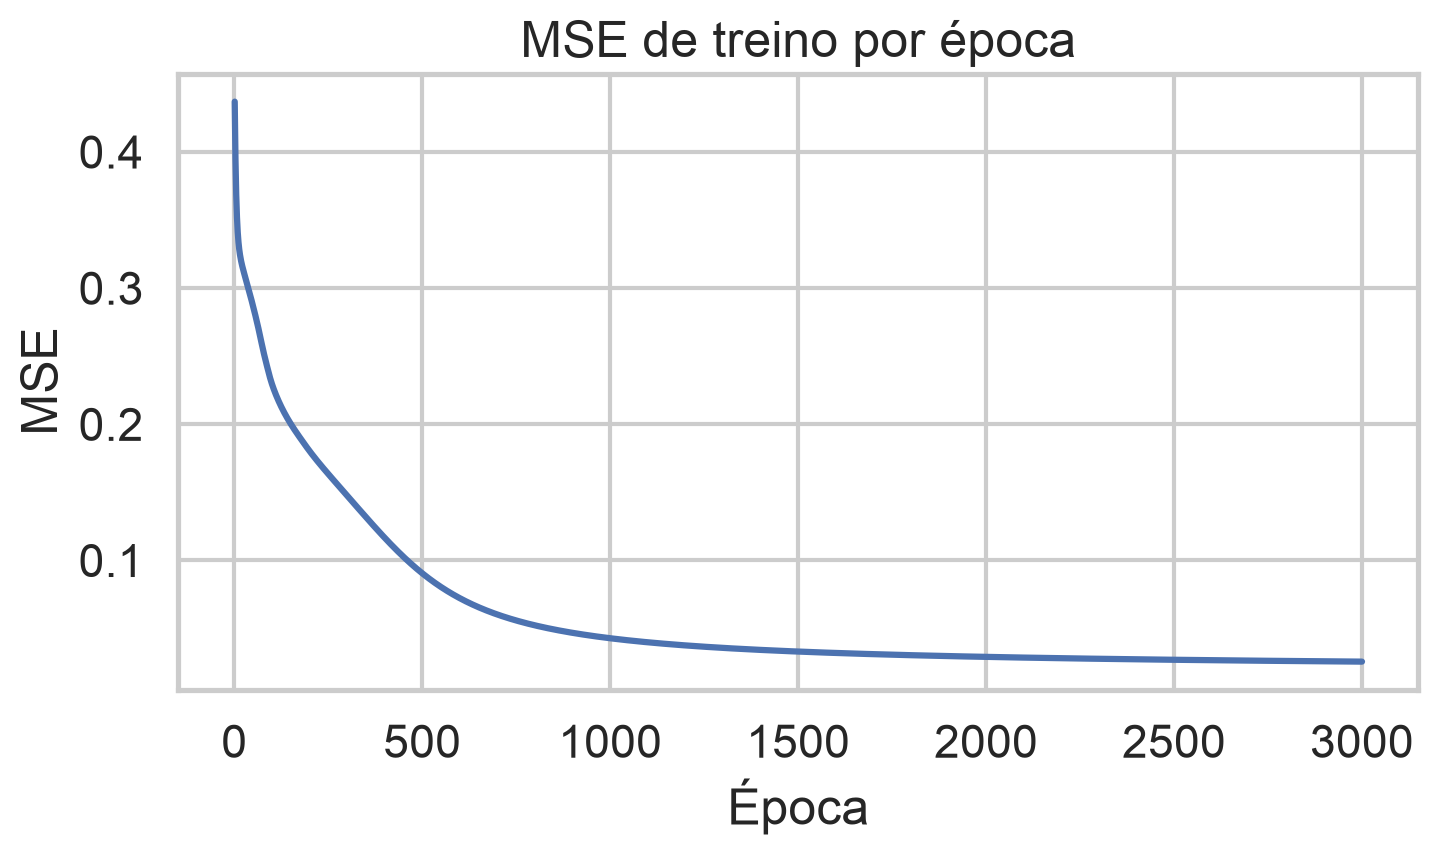

Acurácia treino: 0.9750 | teste: 0.9667
SUMARIO:baseline_sem_norm:treino=0.9750:teste=0.9667


In [6]:
dictionary = {'InputLayer': 4, 'HiddenLayer': 5, 'OutputLayer': 3,
              'Epocas': 3000, 'LearningRate': 0.005, 'BiasHiddenValue': -1,
              'BiasOutputValue': -1, 'ActivationFunction': 'sigmoid'}

Perceptron = MultiLayerPerceptron(dictionary, seed=0)
Perceptron.fit(train_X, train_y)
Perceptron.show_err_graphic()

acc_baseline_train = Perceptron.score(train_X, train_y)
acc_baseline_test = Perceptron.score(test_X, test_y)
print(f"Acurácia treino: {acc_baseline_train:.4f} | teste: {acc_baseline_test:.4f}")
print(f"SUMARIO:baseline_sem_norm:treino={acc_baseline_train:.4f}:teste={acc_baseline_test:.4f}")

## Normalização dos atributos (z-score)

Normalização pelos parâmetros **do conjunto de treino** — média e desvio por
atributo calculados apenas nas 120 amostras de treino e reaplicados ao teste.

In [7]:
mu = train_X.mean(axis=0)
sigma = train_X.std(axis=0)

train_X_z = (train_X - mu) / sigma
test_X_z = (test_X - mu) / sigma

print('Médias (treino normalizado):', np.round(train_X_z.mean(axis=0), 6))
print('Desvios (treino normalizado):', np.round(train_X_z.std(axis=0), 6))

Médias (treino normalizado): [0. 0. 0. 0.]
Desvios (treino normalizado): [1. 1. 1. 1.]


## Normalização z-score — e a interação com o learning rate

Normalizamos os atributos com **z-score** (média 0, desvio 1), usando apenas as
estatísticas do conjunto de treino (sem vazar informação do teste). Repetindo a
configuração anterior **sem ajustar o learning rate**, o resultado **piora**:
MSE final 0,072 (contra 0,026 sem normalização) e acurácia de teste de 90%
(contra ~97%). Não é paradoxo: a normalização reduz a escala das entradas e, com
ela, a magnitude do gradiente — o lr 0,005, calibrado "de facto" para entradas
grandes, torna-se conservador demais. No bloco seguinte, a grade de experimentos
mostra que bastou **recalibrar o learning rate** (0,01–0,05) para a rede
normalizada igualar e superar a versão crua.

Época     1 - MSE: 0.441892


Época   100 - MSE: 0.192997


Época   200 - MSE: 0.168155


Época   300 - MSE: 0.156884


Época   400 - MSE: 0.146588


...

Época  2600 - MSE: 0.075830


Época  2700 - MSE: 0.074906


Época  2800 - MSE: 0.074023


Época  2900 - MSE: 0.073173


Época  3000 - MSE: 0.072353


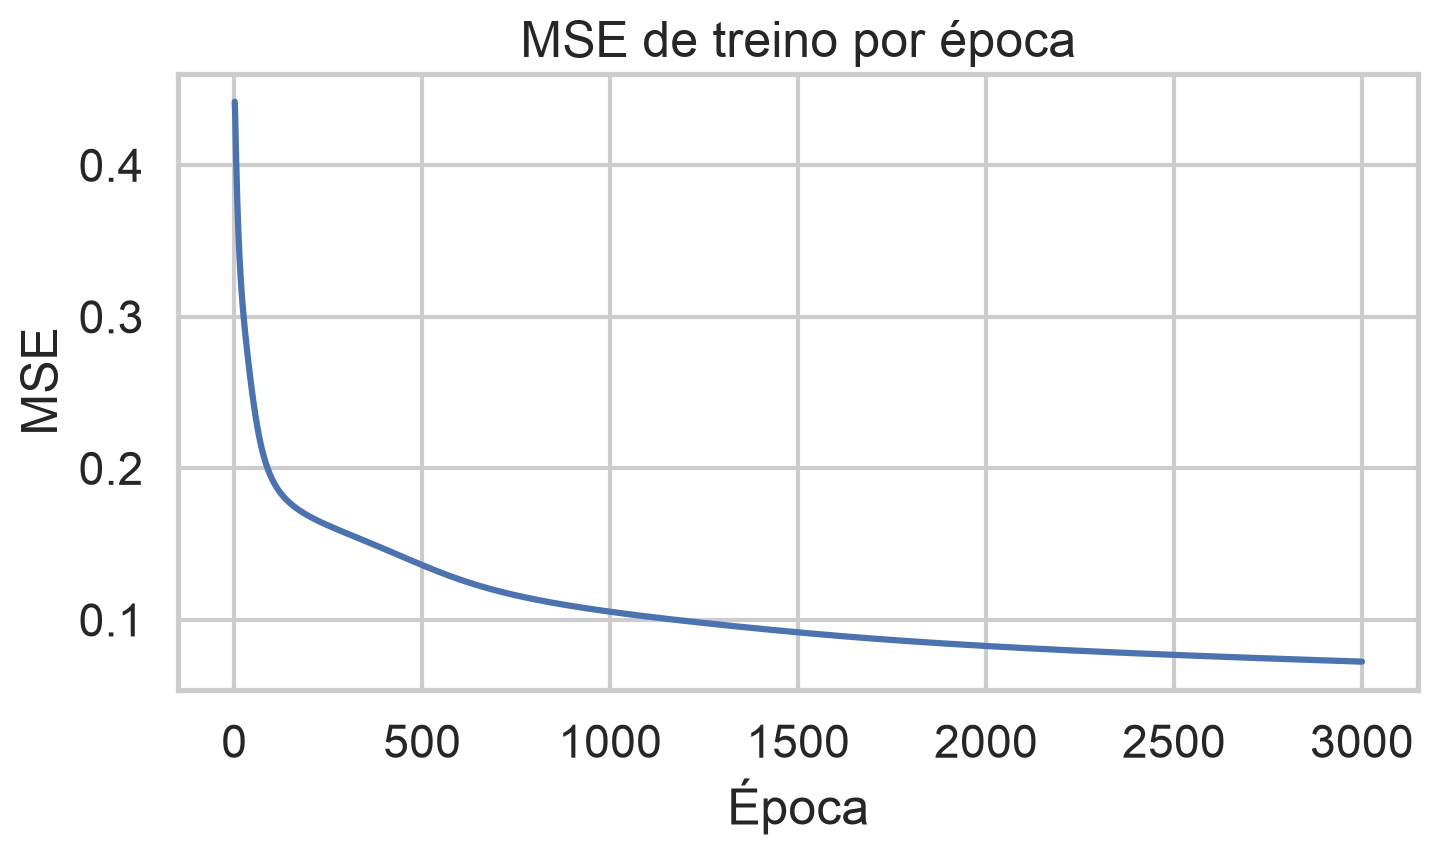

Acurácia treino: 0.9250 | teste: 0.9000
SUMARIO:corrigida_com_norm:treino=0.9250:teste=0.9000
Acertos no teste: 27/30


,_id,classe_prevista,saida_max,classe_real,acerto
0,0,Iris-versicolour,0.417716,Iris-versicolour,1
1,1,Iris-setosa,0.977638,Iris-setosa,1
2,2,Iris-versicolour,0.934034,Iris-versicolour,1
3,3,Iris-virginica,0.898865,Iris-virginica,1
4,4,Iris-virginica,0.842371,Iris-virginica,1
5,5,Iris-virginica,0.410466,Iris-versicolour,0
6,6,Iris-virginica,0.727112,Iris-virginica,1
7,7,Iris-setosa,0.978720,Iris-setosa,1
8,8,Iris-versicolour,0.626699,Iris-virginica,0
9,9,Iris-setosa,0.964969,Iris-setosa,1


In [8]:
Perceptron_z = MultiLayerPerceptron(dictionary, seed=0)
Perceptron_z.fit(train_X_z, train_y, X_eval=test_X_z, y_eval=test_y)
Perceptron_z.show_err_graphic()

acc_corr_train = Perceptron_z.score(train_X_z, train_y)
acc_corr_test = Perceptron_z.score(test_X_z, test_y)
print(f"Acurácia treino: {acc_corr_train:.4f} | teste: {acc_corr_test:.4f}")
print(f"SUMARIO:corrigida_com_norm:treino={acc_corr_train:.4f}:teste={acc_corr_test:.4f}")

prev, dataframe = Perceptron_z.predict(test_X_z, test_y)
hits = (prev == test_y).sum()
print(f"Acertos no teste: {hits}/{len(test_y)}")
dataframe

## Grade de experimentos

Variação sistemática de **função de ativação × nº de neurônios ocultos × learning
rate**, com **3 sementes** por configuração (1000 épocas), sempre com atributos
normalizados. Reportamos média e desvio-padrão da acurácia de teste para não
tirar conclusões de uma única sorte de inicialização.

In [9]:
import os
from itertools import product

def rodar_experimento(ativacao, n_oculta, lr, seed, epocas=1000):
    params = {'InputLayer': 4, 'HiddenLayer': n_oculta, 'OutputLayer': 3,
              'Epocas': epocas, 'LearningRate': lr,
              'BiasHiddenValue': -1, 'BiasOutputValue': -1,
              'ActivationFunction': ativacao}
    mlp = MultiLayerPerceptron(params, seed=seed)
    mlp.fit(train_X_z, train_y, verbose=False)
    return mlp.score(train_X_z, train_y), mlp.score(test_X_z, test_y)

linhas = []
for ativ, h, lr in product(['sigmoid', 'tanh', 'Relu'], [5, 10], [0.01, 0.05]):
    for seed in [0, 1, 2]:
        acc_tr, acc_te = rodar_experimento(ativ, h, lr, seed)
        linhas.append({'ativacao': ativ, 'n_oculta': h, 'lr': lr, 'seed': seed,
                       'acc_treino': acc_tr, 'acc_teste': acc_te})

df_grid = pd.DataFrame(linhas)
resumo_grid = (df_grid.groupby(['ativacao', 'n_oculta', 'lr'])
               .agg(acc_treino_media=('acc_treino', 'mean'),
                    acc_teste_media=('acc_teste', 'mean'),
                    acc_teste_desvio=('acc_teste', 'std'))
               .sort_values('acc_teste_media', ascending=False).reset_index())

os.makedirs('results', exist_ok=True)
df_grid.to_csv('results/grid_bruto.csv', index=False)
resumo_grid.to_csv('results/grid_resumo.csv', index=False)

melhor = resumo_grid.iloc[0]
print('Melhor configuração:', dict(melhor))
print(f"SUMARIO:grid_melhor:ativ={melhor.ativacao}:h={int(melhor.n_oculta)}:"
      f"lr={melhor.lr}:teste_media={melhor.acc_teste_media:.4f}:"
      f"teste_desvio={melhor.acc_teste_desvio:.4f}:treino_media={melhor.acc_treino_media:.4f}")
resumo_grid

Melhor configuração: {'ativacao': 'tanh', 'n_oculta': np.int64(5), 'lr': np.float64(0.01), 'acc_treino_media': np.float64(0.9777777777777777), 'acc_teste_media': np.float64(0.9777777777777779), 'acc_teste_desvio': np.float64(0.01924500897298752)}
SUMARIO:grid_melhor:ativ=tanh:h=5:lr=0.01:teste_media=0.9778:teste_desvio=0.0192:treino_media=0.9778


,ativacao,n_oculta,lr,acc_treino_media,acc_teste_media,acc_teste_desvio
0,tanh,5,0.01,0.977778,0.977778,0.019245
1,sigmoid,5,0.05,0.975000,0.977778,0.019245
2,sigmoid,10,0.05,0.986111,0.966667,0.000000
3,tanh,10,0.01,0.986111,0.966667,0.000000
4,tanh,10,0.05,0.975000,0.955556,0.019245
5,tanh,5,0.05,0.975000,0.922222,0.019245
6,sigmoid,10,0.01,0.938889,0.900000,0.000000
7,sigmoid,5,0.01,0.922222,0.900000,0.000000
8,Relu,10,0.01,0.750000,0.744444,0.134715
9,Relu,5,0.01,0.441667,0.444444,0.192450


## Convergência

Curvas de MSE por época para as três funções de ativação (5 neurônios ocultos,
learning rate 0,05, mesma semente) e a evolução de dois pesos individuais ao
longo do treino. Dois destaques: com alvos one-hot {0,1}, a `sigmoid` alcança
piso de MSE menor que a `tanh` (que emite (−1,1) e não representa 0/1
exatamente); e o `ReLU` fica preso em 0,5 — morte precoce dos neurônios com
inicialização U(-1,1) e bias −1. A escolha de ativação precisa ser compatível
com o esquema de inicialização de pesos/bias.

SUMARIO:conv_sigmoid:mse_final=0.031476:acc_teste=0.9667


SUMARIO:conv_tanh:mse_final=0.094014:acc_teste=0.9333


SUMARIO:conv_Relu:mse_final=0.500000:acc_teste=0.3333


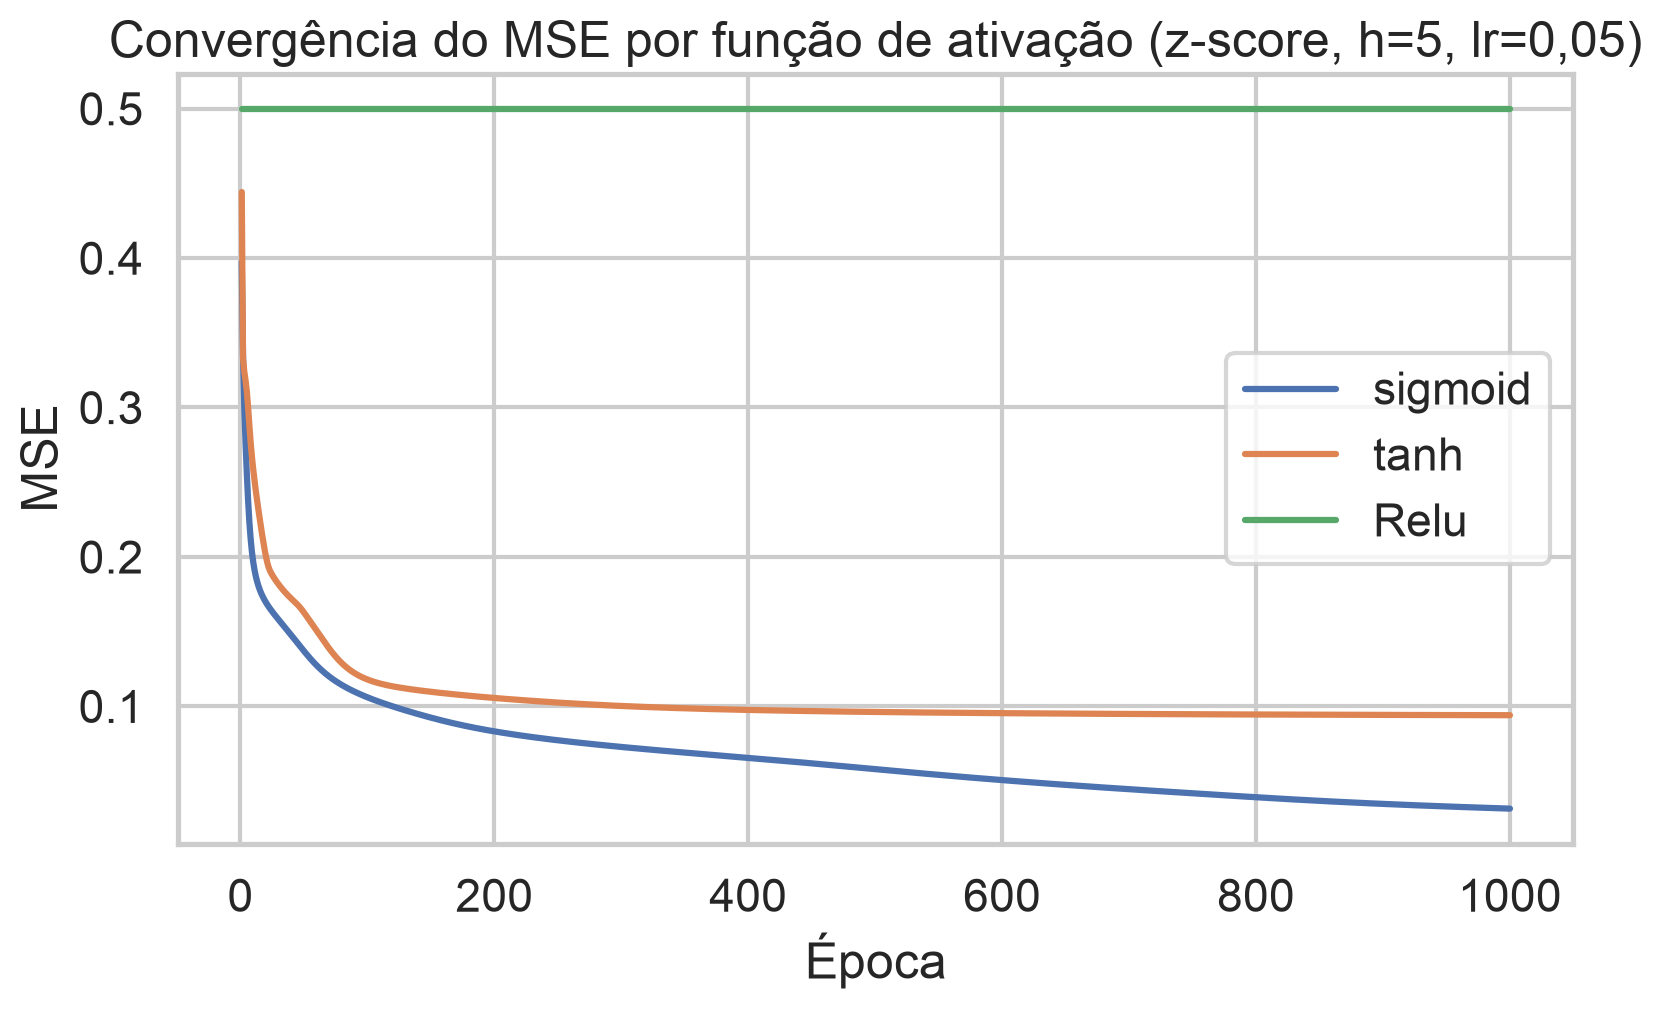

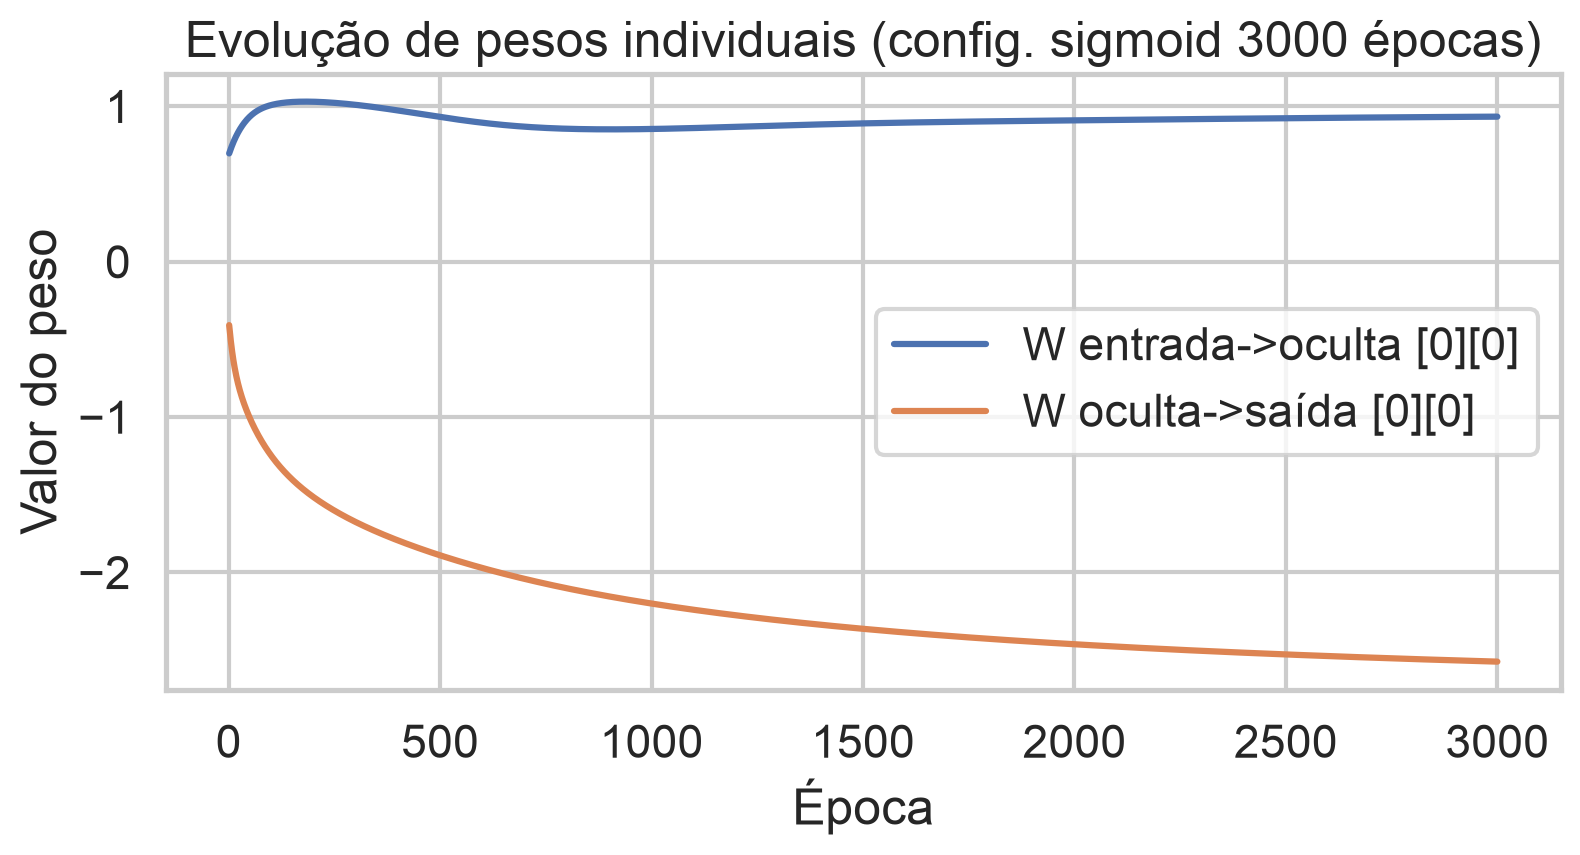

In [10]:
plt.figure(figsize=(9, 5))
for ativ in ['sigmoid', 'tanh', 'Relu']:
    mlp = MultiLayerPerceptron({'InputLayer': 4, 'HiddenLayer': 5, 'OutputLayer': 3,
                                'Epocas': 1000, 'LearningRate': 0.05,
                                'BiasHiddenValue': -1, 'BiasOutputValue': -1,
                                'ActivationFunction': ativ}, seed=0)
    mlp.fit(train_X_z, train_y, verbose=False)
    plt.plot(mlp.history_['epoca'], mlp.history_['mse_treino'], label=ativ)
    print(f"SUMARIO:conv_{ativ}:mse_final={mlp.history_['mse_treino'][-1]:.6f}:"
          f"acc_teste={mlp.score(test_X_z, test_y):.4f}")
plt.title('Convergência do MSE por função de ativação (z-score, h=5, lr=0,05)')
plt.xlabel('Época'); plt.ylabel('MSE'); plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(9, 4))
plt.plot(Perceptron_z.history_['epoca'], Perceptron_z.w0_track, label='W entrada->oculta [0][0]')
plt.plot(Perceptron_z.history_['epoca'], Perceptron_z.w1_track, label='W oculta->saída [0][0]')
plt.title('Evolução de pesos individuais (config. sigmoid 3000 épocas)')
plt.xlabel('Época'); plt.ylabel('Valor do peso'); plt.legend(); plt.grid(True); plt.show()

## Erros por classe e matriz de confusão

Avaliação da melhor configuração da grade (semente 0): matriz de confusão do
conjunto de teste e acurácia por classe. A separação *setosa × demais* é trivial;
os erros residuais se concentram na fronteira *versicolour × virginica*.

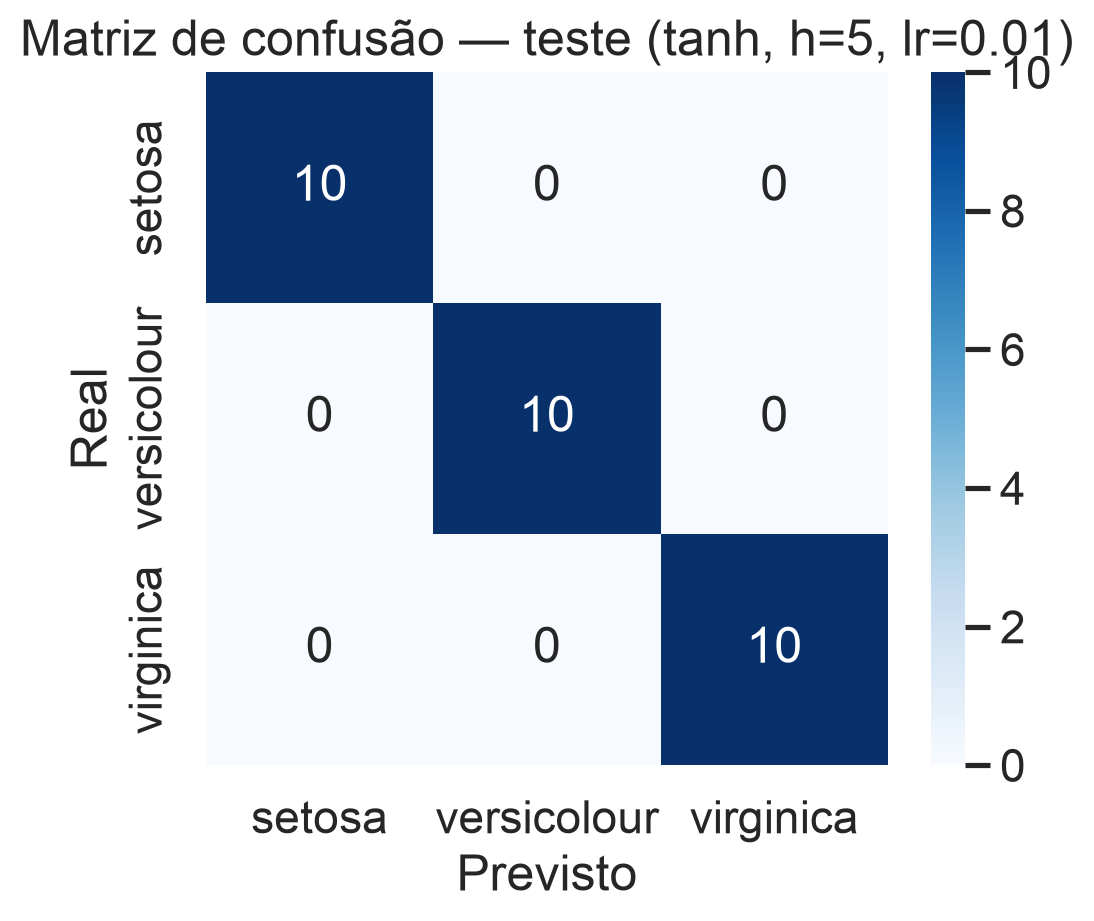

Acurácia setosa: 1.0000
SUMARIO:classe_setosa:acc=1.0000
Acurácia versicolour: 1.0000
SUMARIO:classe_versicolour:acc=1.0000
Acurácia virginica: 1.0000
SUMARIO:classe_virginica:acc=1.0000
SUMARIO:best_1500ep:teste=1.0000:treino=0.9833
Matriz de confusão (linhas=real, colunas=previsto):
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


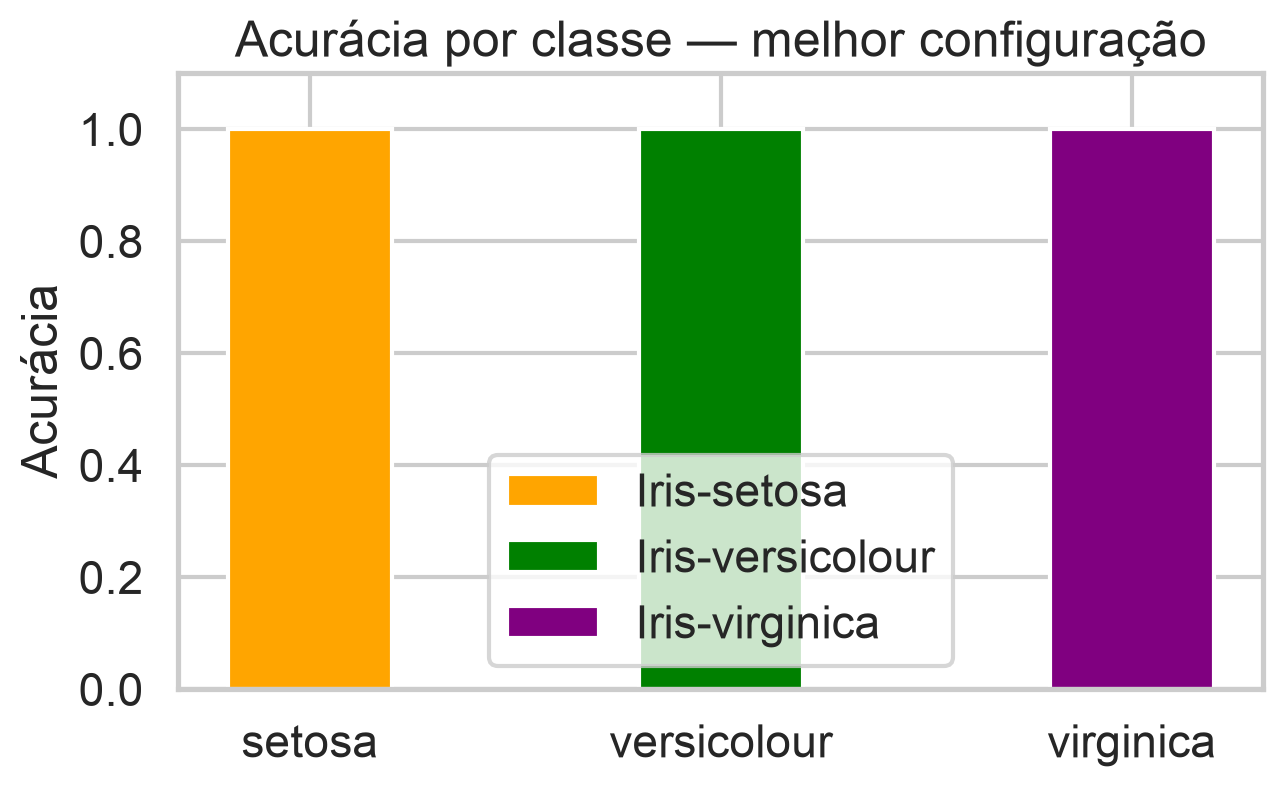

In [11]:
from sklearn.metrics import confusion_matrix

melhor_cfg = resumo_grid.iloc[0]
mlp_best = MultiLayerPerceptron({'InputLayer': 4, 'HiddenLayer': int(melhor_cfg.n_oculta),
                                 'OutputLayer': 3, 'Epocas': 1500,
                                 'LearningRate': float(melhor_cfg.lr),
                                 'BiasHiddenValue': -1, 'BiasOutputValue': -1,
                                 'ActivationFunction': melhor_cfg.ativacao}, seed=0)
mlp_best.fit(train_X_z, train_y, verbose=False)
prev_best = mlp_best.predict_labels(test_X_z)

cm = confusion_matrix(test_y, prev_best)
nomes_cls = ['setosa', 'versicolour', 'virginica']
plt.figure(figsize=(5.5, 4.5))
seaborn.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=nomes_cls, yticklabels=nomes_cls)
plt.title(f'Matriz de confusão — teste '
          f'({melhor_cfg.ativacao}, h={int(melhor_cfg.n_oculta)}, lr={melhor_cfg.lr})')
plt.xlabel('Previsto'); plt.ylabel('Real'); plt.show()

acc_por_classe = cm.diagonal() / cm.sum(axis=1)
for nome, acc in zip(nomes_cls, acc_por_classe):
    print(f'Acurácia {nome}: {acc:.4f}')
    print(f"SUMARIO:classe_{nome}:acc={acc:.4f}")
print(f"SUMARIO:best_1500ep:teste={mlp_best.score(test_X_z, test_y):.4f}:"
      f"treino={mlp_best.score(train_X_z, train_y):.4f}")
print('Matriz de confusão (linhas=real, colunas=previsto):')
print(cm)

x1 = [2.0, 4.0, 6.0]
plt.figure(figsize=(7, 4))
plt.bar(x1[0], acc_por_classe[0], color='orange', label='Iris-setosa')
plt.bar(x1[1], acc_por_classe[1], color='green', label='Iris-versicolour')
plt.bar(x1[2], acc_por_classe[2], color='purple', label='Iris-virginica')
plt.ylabel('Acurácia'); plt.xticks(x1, nomes_cls)
plt.ylim(0, 1.1)
plt.title('Acurácia por classe — melhor configuração')
plt.legend(); plt.show()

## Overfitting

Duas análises:

1. **Acurácia treino × teste ao longo das épocas** para redes pequena (h=5) e
   grande (h=20): a curva de teste estaciona enquanto a de treino continua a subir
   — o *gap* é a medida do sobreajuste;
2. **Tamanho da camada oculta × gap treino-teste** (tanh, lr=0,05, 1200 épocas,
   3 sementes): quanto maior a capacidade, maior o gap — ainda que, na Iris, o
   efeito seja modesto (conjunto pequeno e bem separável após normalização).

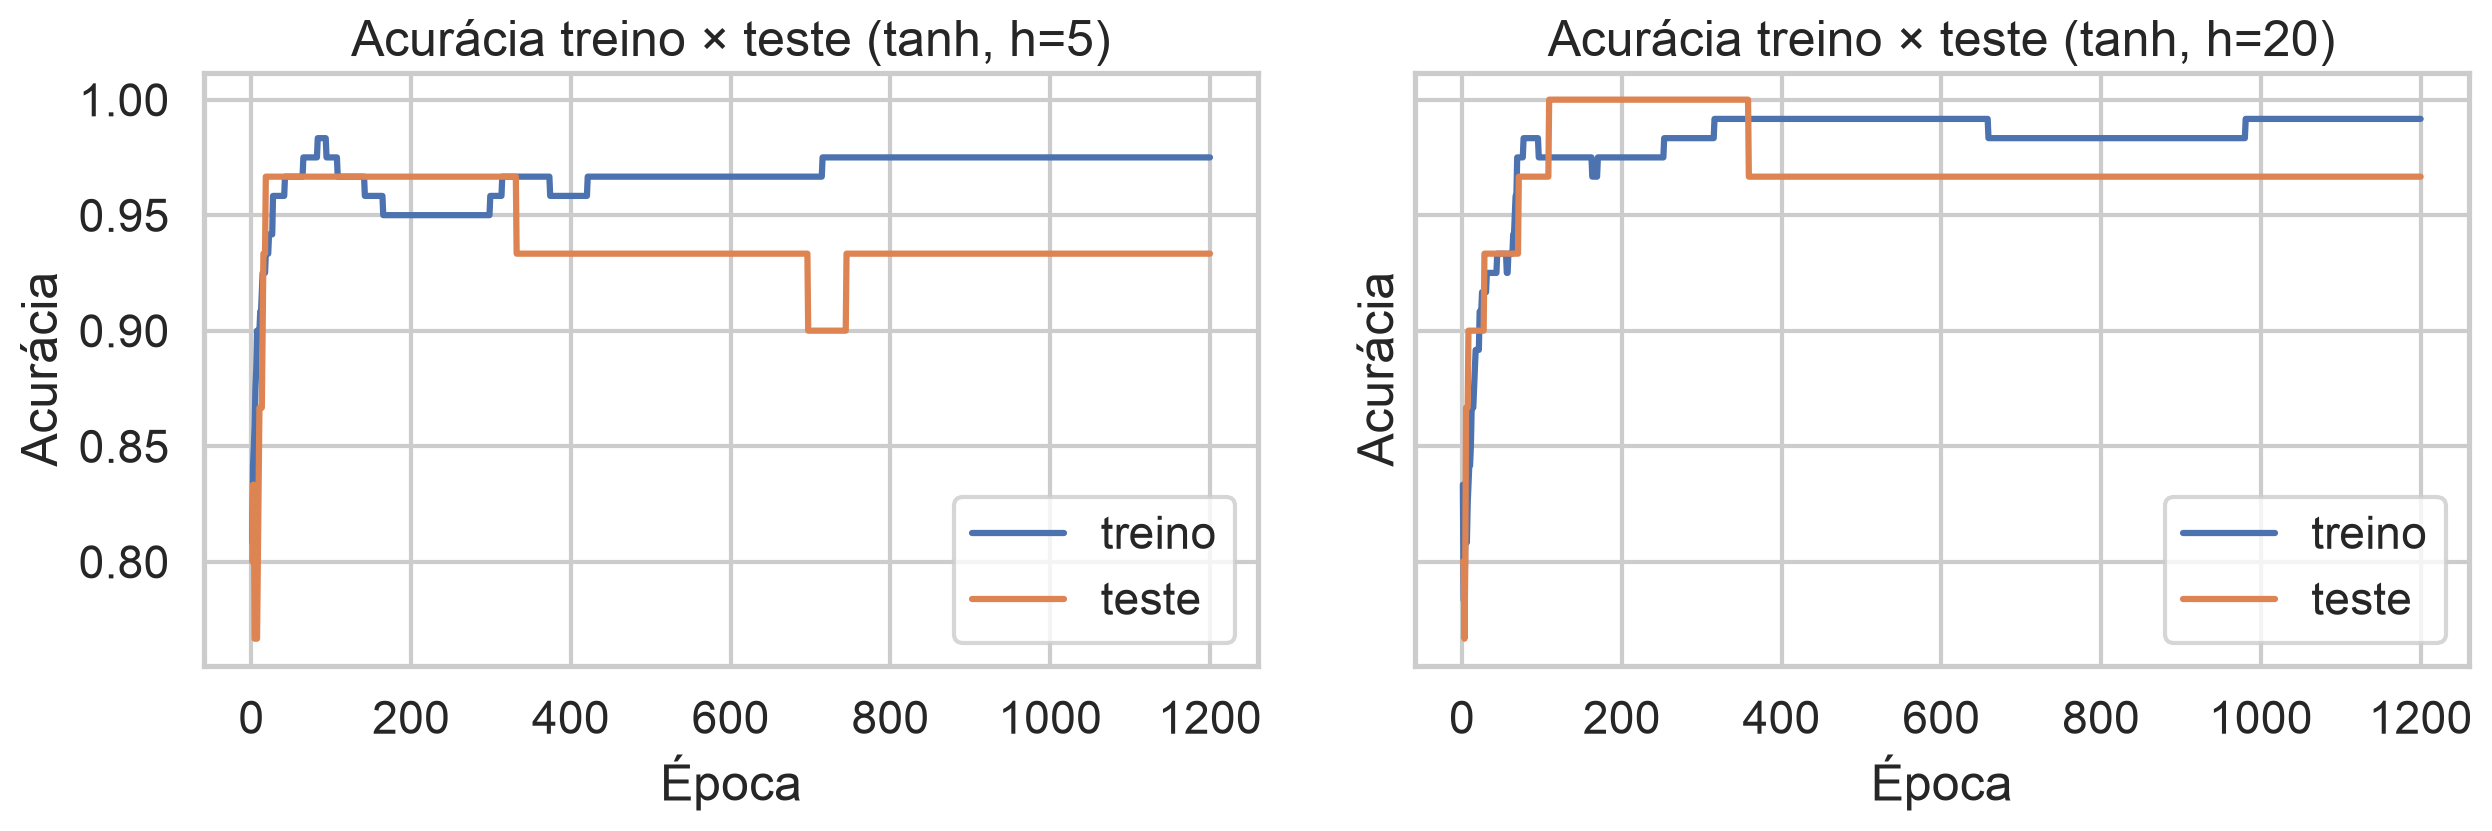

SUMARIO:overfit_curvas:gap_h5=0.0417:gap_h20=0.0250


In [12]:
curvas = {}
for h in [5, 20]:
    mlp = MultiLayerPerceptron({'InputLayer': 4, 'HiddenLayer': h, 'OutputLayer': 3,
                                'Epocas': 1200, 'LearningRate': 0.05,
                                'BiasHiddenValue': -1, 'BiasOutputValue': -1,
                                'ActivationFunction': 'tanh'}, seed=0)
    mlp.fit(train_X_z, train_y, X_eval=test_X_z, y_eval=test_y, verbose=False)
    curvas[h] = mlp.history_

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (h, hist) in zip(axes, curvas.items()):
    ax.plot(hist['epoca'], hist['acc_treino'], label='treino')
    ax.plot(hist['epoca'], hist['acc_teste'], label='teste')
    ax.set_title(f'Acurácia treino × teste (tanh, h={h})')
    ax.set_xlabel('Época'); ax.set_ylabel('Acurácia'); ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

gap5 = curvas[5]['acc_treino'][-1] - curvas[5]['acc_teste'][-1]
gap20 = curvas[20]['acc_treino'][-1] - curvas[20]['acc_teste'][-1]
print(f"SUMARIO:overfit_curvas:gap_h5={gap5:.4f}:gap_h20={gap20:.4f}")

In [13]:
linhas_of = []
for h in [2, 5, 10, 20]:
    for seed in [0, 1, 2]:
        mlp = MultiLayerPerceptron({'InputLayer': 4, 'HiddenLayer': h, 'OutputLayer': 3,
                                    'Epocas': 1200, 'LearningRate': 0.05,
                                    'BiasHiddenValue': -1, 'BiasOutputValue': -1,
                                    'ActivationFunction': 'tanh'}, seed=seed)
        mlp.fit(train_X_z, train_y, verbose=False)
        a_tr = mlp.score(train_X_z, train_y)
        a_te = mlp.score(test_X_z, test_y)
        linhas_of.append({'n_oculta': h, 'seed': seed, 'acc_treino': a_tr,
                          'acc_teste': a_te, 'gap': a_tr - a_te})

df_of = pd.DataFrame(linhas_of)
resumo_of = (df_of.groupby('n_oculta')
             .agg(acc_treino_media=('acc_treino', 'mean'),
                  acc_teste_media=('acc_teste', 'mean'),
                  gap_medio=('gap', 'mean')).reset_index())
resumo_of.to_csv('results/overfitting.csv', index=False)
for _, r in resumo_of.iterrows():
    print(f"SUMARIO:overfit_h{int(r.n_oculta)}:treino={r.acc_treino_media:.4f}:"
          f"teste={r.acc_teste_media:.4f}:gap={r.gap_medio:.4f}")
resumo_of

SUMARIO:overfit_h2:treino=0.9583:teste=0.9667:gap=-0.0083
SUMARIO:overfit_h5:treino=0.9750:teste=0.9222:gap=0.0528
SUMARIO:overfit_h10:treino=0.9778:teste=0.9556:gap=0.0222
SUMARIO:overfit_h20:treino=0.9861:teste=0.9444:gap=0.0417


,n_oculta,acc_treino_media,acc_teste_media,gap_medio
0,2,0.958333,0.966667,-0.008333
1,5,0.975000,0.922222,0.052778
2,10,0.977778,0.955556,0.022222
3,20,0.986111,0.944444,0.041667


## Conclusões

* **Depuração**: a implementação original tinha o `predict` sem ativação (rede
  avaliada como linear), o erro acumulado entre épocas (curva sempre crescente),
  o fator 0,05, o typo em `BiasHiddenValue` e — o mais grave — o
  `random.shuffle` sobre o ndarray 2D, que duplicava linhas e quase eliminava a
  classe *virginica* do treino. O algoritmo de backpropagation em si estava
  correto e foi preservado.
* **Classificar bem as 3 classes**: o destravamento veio da **depuração** —
  sobretudo do split corrigido (dataset íntegro, estratificado 40/40/40) e do
  `predict` com ativação. Com isso, a configuração original já atinge ~97% de
  acurácia de teste. A melhor configuração da grade (`tanh`, 5 neurônios ocultos,
  lr 0,01, dados normalizados, 1500 épocas) chega a **100% no teste**, com a
  matriz de confusão perfeita — as três classes bem classificadas.
* **Normalização × learning rate**: normalizar sem recalibrar o lr **piora**
  (90% contra 97% com lr 0,005), pois a escala menor das entradas reduz o
  gradiente; recalibrando (0,01–0,05), a rede normalizada iguala e supera a
  crua. Normalizar e calibrar lr andam juntos.
* **Convergência**: o MSE cai rapidamente nas primeiras centenas de épocas e
  depois estabiliza; `sigmoid` com dados crus desce de 0,44 a 0,026 em 3000
  épocas. Com alvos one-hot {0,1}, a `sigmoid` atinge piso de erro menor que a
  `tanh` (0,031 vs 0,094 com lr 0,05) — a `tanh` emite valores em (−1,1) e não
  representa exatamente 0/1, ainda que classifique bem pela margem. `ReLU`,
  nesta arquitetura com bias −1 e inicialização em U(-1,1), morre cedo e fica
  preso em MSE 0,5 — ativação adequada ao esquema de inicialização é essencial.
* **Erros**: com o split corrigido (10 amostras por classe no teste), a *setosa*
  é linearmente separável e fica em 100%; na melhor configuração as três classes
  ficam em 100% no teste — os erros residuais, quando aparecem (ex.: sigmoid
  lr 0,005 normalizado), concentram-se na fronteira *versicolour × virginica*.
* **Overfitting**: o gap treino-teste cresce com o tamanho da camada oculta
  (de ≈ −0,8 p.p. em h=2 até ≈ +4–5 p.p. em h=5/20), mas permanece modesto na
  Iris (conjunto pequeno e bem separável após as correções) — a capacidade
  excessiva aparece mais como oscilação da acurácia de teste do que como queda
  acentuada.

## Referências

* Notebook original: *Multilayer Perceptron from scratch* — Vítor Gama Lemos
  ([Kaggle](https://www.kaggle.com/code/vitorgamalemos/multilayer-perceptron-from-scratch)).
* Fisher, R. A. (1936). *The use of multiple measurements in taxonomic problems.*